# ITCS 6169/8169 — Assignment 3: one-shot with image prototypes (CLIP, SigLIP, DINOv2)

**One-shot** here means exactly **one labeled training image per class** (16 labeled images in total). Each labeled image is
embedded by a frozen pretrained model; that vector (the class **prototype**) represents its class, and every test image is
assigned to the class whose prototype is most similar (cosine similarity). Nothing is trained or fitted.

- **CLIP and SigLIP** (image tower) and **DINOv2** (image-only model, often strong at image-to-image similarity) are compared.
- **Which image?** With one sample per class, the choice matters a lot. Each support set is drawn at random with a seeded generator
  from the file names in each class folder (no image is looked at, no other label is used), and the experiment is repeated for
  `N_SEEDS` different support sets. Results are reported as mean ± std over seeds, plus the declared headline seed.
- **Augmented prototypes.** Besides the original image, `N_AUG` augmented copies (crop, flip, slight brightness/contrast) are
  embedded and averaged into the prototype. Both versions (`noaug` = original only, `aug`) are reported.
- **Rules check.** Only the 16 chosen training images are ever opened; the other training images are never read (only their file
  names are listed to draw a random one). Test images are used for evaluation only.
- **Extra section at the end (optional):** combine the text classifier (zero-shot) with the image prototypes, including mixing
  the text side of one model with the prototypes of another (for example SigLIP text + DINOv2 prototypes). The mixing weight is
  fixed in advance (0.5); there is no labeled validation set to tune it.

**No labeled validation data exists in this setting**, so every comparison is measured on the test set. Phrases, templates,
seeds, augmentation settings and the headline configuration are fixed before running, and every configuration is printed.

**Setup (once, in your venv):** `pip install "transformers>=4.49,<5" sentencepiece protobuf`. The first run downloads each model
from Hugging Face. Embeddings are cached in `a3_cache/`, so re-running is fast and a crash can be resumed. The test-image embeddings share a cache
file with the zero-shot notebook (CLIP and SigLIP), so they are not computed twice.

**Run time (my estimate, not measured: I could not run the models where I wrote this).** Each model embeds the 400 test images plus
`N_SEEDS x 16 x (1 + N_AUG)` support views (720 with the defaults). On a CPU, SigLIP so400m is the slow one, plausibly about an hour in total here,
and the two "large" models (CLIP L/14, DINOv2-large) maybe 10–20 minutes each. For a quick first pass set `N_SEEDS = 3` and `N_AUG = 4` and/or remove
`'siglip-so400m-384'` from `ENABLED_MODELS`; cached embeddings for the headline seed are reused when you later increase `N_SEEDS`.

In [1]:
# Core imports
import os, sys, gc, json, csv, time, math, random, warnings
from pathlib import Path

os.environ.setdefault('HF_HUB_DISABLE_SYMLINKS_WARNING', '1')     # Windows: silence the symlink notice

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn.functional as F
from torchvision import datasets

try:
    import torch_directml  # AMD GPU on Windows (optional)
    HAS_DML = torch_directml.is_available()
except ImportError:
    HAS_DML = False

try:
    import transformers
    from transformers import AutoModel, AutoProcessor, AutoImageProcessor
except ImportError as e:
    raise ImportError('This notebook needs Hugging Face transformers. In your venv run:\n'
                      '    pip install "transformers>=4.49,<5" sentencepiece protobuf') from e

print('PyTorch        :', torch.__version__)
print('transformers   :', transformers.__version__)
print('CUDA available :', torch.cuda.is_available())
print('DirectML       :', HAS_DML)
print('CPU threads    :', torch.get_num_threads())

d:\School\13 - Fall 2026\ITCS 6169\assignment3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch        : 2.15.0+cpu
transformers   : 4.57.6
CUDA available : False
DirectML       : False
CPU threads    : 8


## Paths and device

In [2]:
PROJECT_ROOT = Path('.')                       # run the notebook from your project folder
TRAIN_ROOT   = PROJECT_ROOT / 'data' / 'train'
TEST_ROOT    = PROJECT_ROOT / 'data' / 'test'
CACHE_DIR    = PROJECT_ROOT / 'a3_cache'       # embeddings are cached here, so a crash or re-run resumes quickly
RESULTS_DIR  = PROJECT_ROOT / 'a3_results'
CACHE_DIR.mkdir(exist_ok=True); RESULTS_DIR.mkdir(exist_ok=True)

EXPECTED_CLASSES = ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen',
                    'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
NUM_CLASSES = len(EXPECTED_CLASSES)
print('Project root:', PROJECT_ROOT.resolve())

Project root: D:\School\13 - Fall 2026\ITCS 6169\assignment3


In [3]:
# Inference on CPU is the default: only a few hundred images are embedded, and CPU is the safe choice
# (DirectML has needed workarounds in earlier assignments). Set USE_GPU = True to try the GPU; every model
# is then checked against the CPU embeddings first and falls back to CPU if they disagree.
USE_GPU = False
BATCH_SIZE = 8              # lower this if a large model runs out of memory

def pick_device():
    if not USE_GPU:
        return torch.device('cpu')
    if torch.cuda.is_available():
        return torch.device('cuda')
    if HAS_DML:
        return torch_directml.device()
    return torch.device('cpu')

DEVICE = pick_device()
print('Device:', DEVICE)

Device: cpu


## Configuration
`FEATURE_VARIANTS`: CLIP and SigLIP give one image embedding (`img`). DINOv2 gives three: the CLS token (`cls`), the mean of the
patch tokens (`patch`), and both concatenated (`cls_patch`). The declared headline variant for DINOv2 is `cls`.

In [4]:
MODEL_SPECS = {
    'clip-b16':           dict(kind='clip',   repo='openai/clip-vit-base-patch16'),
    'clip-l14':           dict(kind='clip',   repo='openai/clip-vit-large-patch14'),
    'siglip-b16-224':     dict(kind='siglip', repo='google/siglip-base-patch16-224'),
    'siglip-so400m-384':  dict(kind='siglip', repo='google/siglip-so400m-patch14-384'),
    'dinov2-base':        dict(kind='dino',   repo='facebook/dinov2-base'),
    'dinov2-large':       dict(kind='dino',   repo='facebook/dinov2-large'),
    # ---- optional extras ----
    'dinov2-small':       dict(kind='dino',   repo='facebook/dinov2-small'),
    'dinov2-giant':       dict(kind='dino',   repo='facebook/dinov2-giant'),
    'clip-l14-laion2b':   dict(kind='clip',   repo='laion/CLIP-ViT-L-14-laion2B-s32B-b82K'),
    'siglip2-so400m-384': dict(kind='siglip', repo='google/siglip2-so400m-patch14-384'),
}
ENABLED_MODELS = ['clip-b16', 'clip-l14', 'siglip-b16-224', 'siglip-so400m-384', 'dinov2-base', 'dinov2-large']   # drop so400m for a quicker run

FEATURE_VARIANTS = {'clip': ['img'], 'siglip': ['img'], 'dino': ['cls', 'patch', 'cls_patch']}
HEADLINE_VARIANT = {'clip': 'img', 'siglip': 'img', 'dino': 'cls'}

N_SEEDS       = 5        # number of different support sets (one labeled image per class each)
HEADLINE_SEED = 0        # declared in advance; used for the plots and error analysis
N_AUG         = 8        # augmented copies per labeled image (in addition to the original); cache files are keyed on this value

RUN_BLEND   = True       # optional last section: text classifier + image prototypes
BLEND_ALPHA = 0.5        # weight on the text scores, fixed in advance (1 - alpha goes to the prototype scores)

## Test data and the training-set listing
The training folders are only *listed* (file names) so a random image per class can be drawn.

In [5]:
test_ds = datasets.ImageFolder(TEST_ROOT)
assert test_ds.classes == EXPECTED_CLASSES, f'test class folders differ from the expected 16: {test_ds.classes}'
test_paths  = [p for p, _ in test_ds.samples]
test_labels = np.array([y for _, y in test_ds.samples])

def load_rgb(p):
    with Image.open(p) as im:
        return im.convert('RGB')

test_images = [load_rgb(p) for p in test_paths]
sizes = np.array([im.size for im in test_images])
print(f'{len(test_images)} test images | width {sizes[:, 0].min()}-{sizes[:, 0].max()} px, height {sizes[:, 1].min()}-{sizes[:, 1].max()} px')

train_classes = sorted(p.name for p in TRAIN_ROOT.iterdir() if p.is_dir())
assert train_classes == EXPECTED_CLASSES, f'train class folders differ from the expected 16: {train_classes}'
print(f'chance accuracy: {1 / NUM_CLASSES:.4f}')

400 test images | width 220-750 px, height 200-743 px
chance accuracy: 0.0625


## Helpers

In [6]:
# ---- analysis helpers (numpy only) ----
def l2norm(x, axis=-1):
    return x / (np.linalg.norm(x, axis=axis, keepdims=True) + 1e-12)

def accuracy(pred, y):
    return float((np.asarray(pred) == np.asarray(y)).mean())

def binomial_se(p, n):
    return math.sqrt(max(p * (1 - p), 0.0) / n)

def per_class_accuracy(pred, y, num_classes):
    pred, y = np.asarray(pred), np.asarray(y)
    return [float((pred[y == c] == c).mean()) if (y == c).any() else float('nan') for c in range(num_classes)]

def confusion_matrix(pred, y, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    np.add.at(cm, (np.asarray(y), np.asarray(pred)), 1)          # rows = true class, columns = predicted class
    return cm

def top_confusions(cm, names, k=6):
    off = [(int(cm[i, j]), names[i], names[j]) for i in range(len(names)) for j in range(len(names)) if i != j and cm[i, j] > 0]
    return sorted(off, reverse=True)[:k]

def zscore_rows(s):
    """Standardise each row (one test image) across the classes, so two score types can be added fairly."""
    return (s - s.mean(1, keepdims=True)) / (s.std(1, keepdims=True) + 1e-8)

def make_prototypes(view_embs, mode):
    """view_embs: [classes, views, dim], every view L2-normalised, view 0 = the original image.
    'noaug' = the original image only; 'aug' = mean over the original and its augmented views."""
    p = view_embs[:, 0] if mode == 'noaug' else view_embs.mean(1)
    return l2norm(p)

def mean_std(values):
    v = np.asarray(values, dtype=float)
    return float(v.mean()), (float(v.std(ddof=1)) if len(v) > 1 else float('nan'))

In [7]:
# ---- small on-disk cache for embeddings (numpy only) ----
def cached_npz(path, build_fn, check=None):
    """Load {name: array} from `path` if it exists and passes `check`, otherwise build it and save it."""
    path = Path(path)
    if path.exists():
        try:
            with np.load(path, allow_pickle=False) as z:
                data = {k: z[k] for k in z.files}
            if check is None or check(data):
                return data
            print(f'  cache {path.name} is stale -> recomputing')
        except Exception as e:
            print(f'  cache {path.name} unreadable ({e}) -> recomputing')
    data = build_fn()
    np.savez_compressed(path, **data)
    return data

In [8]:
# ---- model loading and embedding (Hugging Face transformers) ----
def _unwrap(x):
    """get_*_features returns a tensor in transformers 4.x; be tolerant of output objects."""
    if torch.is_tensor(x):
        return x
    for attr in ('image_embeds', 'text_embeds', 'pooler_output'):
        v = getattr(x, attr, None)
        if v is not None:
            return v
    raise TypeError(f'unexpected feature output type: {type(x)}')

def load_bundle(key):
    spec = MODEL_SPECS[key]
    t0 = time.time()
    model = AutoModel.from_pretrained(spec['repo']).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    proc = AutoImageProcessor.from_pretrained(spec['repo']) if spec['kind'] == 'dino' else AutoProcessor.from_pretrained(spec['repo'])
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"loaded {key}  ({spec['repo']}, {n_params:.0f}M parameters, {time.time() - t0:.0f}s)")
    return dict(key=key, kind=spec['kind'], model=model, proc=proc)

@torch.no_grad()
def embed_images(bundle, images, device, batch_size=8, quiet=False):
    """Returns {variant: array[N, D]} of L2-normalised embeddings.
    CLIP / SigLIP -> {'img'};  DINOv2 -> {'cls', 'patch', 'cls_patch'}."""
    model, kind, proc = bundle['model'].to(device), bundle['kind'], bundle['proc']
    chunks, t0, n_batches = {}, time.time(), math.ceil(len(images) / batch_size)
    for bi, i in enumerate(range(0, len(images), batch_size)):
        inputs = proc(images=images[i:i + batch_size], return_tensors='pt')
        inputs = {k: v.to(device) for k, v in inputs.items()}
        if kind == 'dino':
            h = model(pixel_values=inputs['pixel_values']).last_hidden_state.float()
            c, p = F.normalize(h[:, 0], dim=-1), F.normalize(h[:, 1:].mean(1), dim=-1)
            feats = {'cls': c, 'patch': p, 'cls_patch': F.normalize(torch.cat([c, p], dim=-1), dim=-1)}
        else:
            feats = {'img': F.normalize(_unwrap(model.get_image_features(**inputs)).float(), dim=-1)}
        for k, v in feats.items():
            chunks.setdefault(k, []).append(v.cpu())
        if not quiet and (bi == 1 or (bi + 1) % max(1, n_batches // 5) == 0 or bi + 1 == n_batches):
            el = time.time() - t0
            done = min(i + batch_size, len(images))
            print(f'    {done}/{len(images)} images | {el:.0f}s elapsed | projected total {el / done * len(images):.0f}s')
    return {k: torch.cat(v).numpy() for k, v in chunks.items()}

@torch.no_grad()
def embed_texts(bundle, texts, device, batch_size=64):
    """L2-normalised text embeddings [N, D] for CLIP / SigLIP models."""
    model, kind, proc = bundle['model'].to(device), bundle['kind'], bundle['proc']
    out = []
    for i in range(0, len(texts), batch_size):
        chunk = texts[i:i + batch_size]
        if kind == 'siglip':       # SigLIP models were trained on lower-case text padded to 64 tokens, without a mask
            tok = proc(text=[t.lower() for t in chunk], padding='max_length', max_length=64, truncation=True, return_tensors='pt')
            f = model.get_text_features(input_ids=tok['input_ids'].to(device))
        else:                      # CLIP
            tok = proc(text=chunk, padding=True, truncation=True, max_length=77, return_tensors='pt')
            f = model.get_text_features(input_ids=tok['input_ids'].to(device), attention_mask=tok['attention_mask'].to(device))
        out.append(F.normalize(_unwrap(f).float(), dim=-1).cpu())
    return torch.cat(out).numpy()

def choose_run_device(bundle, sample_images):
    """CPU unless USE_GPU is on and the GPU embeddings match the CPU ones (cosine > 0.999 on a few images)."""
    if DEVICE.type == 'cpu':
        return DEVICE
    cpu = torch.device('cpu')
    a = embed_images(bundle, sample_images, cpu, 4, quiet=True)
    b = embed_images(bundle, sample_images, DEVICE, 4, quiet=True)
    k = next(iter(a))
    min_cos = float((a[k] * b[k]).sum(1).min())
    if min_cos > 0.999:
        print(f'  GPU check passed (min cosine vs CPU = {min_cos:.5f}) -> using {DEVICE}')
        return DEVICE
    print(f'  GPU check FAILED (min cosine vs CPU = {min_cos:.4f}) -> falling back to CPU')
    bundle['model'].to(cpu)
    return cpu

In [9]:
# ---- class-name phrases and prompt templates (written before any result was looked at) ----
import re, hashlib

def raw_phrase(folder_name):
    """Mechanical: split the CamelCase folder name and add an article ('LivingRoom' -> 'a living room')."""
    words = re.sub(r'(?<!^)(?=[A-Z])', ' ', folder_name).lower()
    return ('an ' if words[0] in 'aeiou' else 'a ') + words

# Hand-written, more descriptive phrases (articles included). Fixed in advance, never tuned on results.
DESCRIPTIVE = {
    'Bedroom':      'a bedroom',
    'Coast':        'a coast by the sea',
    'Flower':       'a flower',
    'Forest':       'a forest',
    'Highway':      'a highway',
    'Industrial':   'an industrial area',
    'InsideCity':   'the inside of a city with buildings',
    'Kitchen':      'a kitchen',
    'LivingRoom':   'a living room',
    'Mountain':     'a mountain',
    'Office':       'an office',
    'OpenCountry':  'open country with fields',
    'Store':        'the inside of a store',
    'Street':       'a street',
    'Suburb':       'a suburban residential area',
    'TallBuilding': 'a tall building, a skyscraper',
}
assert list(DESCRIPTIVE) == EXPECTED_CLASSES

PHRASES = {'raw': [raw_phrase(c) for c in EXPECTED_CLASSES],
           'descriptive': [DESCRIPTIVE[c] for c in EXPECTED_CLASSES]}

TEMPLATES = {
    'single': ['a photo of {}.'],
    'ensemble': ['a photo of {}.', 'a picture of {}.', 'an image of {}.', 'a photo of {}, a type of scene.',
                 'a photo taken of {}.', 'a low resolution photo of {}.', 'a cropped photo of {}.'],
}

# fingerprint of the prompts: cached text embeddings are recomputed automatically if you edit any phrase or template
PROMPT_SIG = hashlib.md5(json.dumps([PHRASES, TEMPLATES], sort_keys=True).encode()).hexdigest()

def class_text_embeddings(bundle, naming, tmpl, device):
    """[classes, D]: mean of the normalised template embeddings per class, re-normalised."""
    phrases, templates = PHRASES[naming], TEMPLATES[tmpl]
    texts = [t.format(p) for p in phrases for t in templates]
    emb = embed_texts(bundle, texts, device).reshape(len(phrases), len(templates), -1).mean(1)
    return l2norm(emb)

print('example prompts for', EXPECTED_CLASSES[6], '->')
for naming in PHRASES:
    print(f'  [{naming}]', [t.format(PHRASES[naming][6]) for t in TEMPLATES['ensemble'][:3]], '...')

example prompts for InsideCity ->
  [raw] ['a photo of an inside city.', 'a picture of an inside city.', 'an image of an inside city.'] ...
  [descriptive] ['a photo of the inside of a city with buildings.', 'a picture of the inside of a city with buildings.', 'an image of the inside of a city with buildings.'] ...


## The support sets
For each seed, one image per class is drawn at random, then the chosen image is opened and `N_AUG` augmented copies are made
(random crop of 60–100% of the image, horizontal flip, brightness/contrast ±20%, with fixed random seeds, so every model sees
identical views). The chosen file names are saved to `a3_results/oneshot_support_sets.json`.

In [10]:
# ---- choosing the one labeled image per class ----
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}

def list_class_images(cls):
    """File names only: the images themselves are not opened here."""
    return sorted(p for p in (TRAIN_ROOT / cls).iterdir() if p.suffix.lower() in IMG_EXT)

def pick_support(seed, list_fn, classes):
    """One image per class, drawn at random with a seeded generator (no look at the images, no use of any other label)."""
    rng = np.random.default_rng(1000 + seed)
    chosen = {}
    for c in classes:
        files = list_fn(c)
        chosen[c] = files[int(rng.integers(len(files)))]
    return chosen

In [11]:
import torchvision.transforms as T

def make_views(path, seed, class_index, n_aug):
    """[original] + n_aug augmented copies of the chosen image (deterministic for a given seed and class)."""
    img = load_rgb(path)
    W, H = img.size
    aug = T.Compose([T.RandomResizedCrop(size=(H, W), scale=(0.6, 1.0), ratio=(0.75, 4 / 3)),
                     T.RandomHorizontalFlip(0.5),
                     T.ColorJitter(brightness=0.2, contrast=0.2)])
    saved = torch.get_rng_state()
    torch.manual_seed(100_000 * seed + class_index)
    views = [img] + [aug(img) for _ in range(n_aug)]
    torch.set_rng_state(saved)
    return views

support = {}
for s in range(N_SEEDS):
    chosen = pick_support(s, list_class_images, EXPECTED_CLASSES)
    support[s] = dict(paths=[chosen[c] for c in EXPECTED_CLASSES],
                      views=[make_views(chosen[c], s, ci, N_AUG) for ci, c in enumerate(EXPECTED_CLASSES)])
(RESULTS_DIR / 'oneshot_support_sets.json').write_text(
    json.dumps({str(s): [str(p) for p in support[s]['paths']] for s in support}, indent=1))
print(f'{N_SEEDS} support sets x {NUM_CLASSES} classes x {1 + N_AUG} views | headline seed {HEADLINE_SEED}')
for s in range(N_SEEDS):
    print(f'  seed {s}:', ', '.join(p.name for p in support[s]['paths'][:4]), '...')

5 support sets x 16 classes x 9 views | headline seed 0
  seed 0: image_0031.jpg, image_0125.jpg, image_0178.jpg, image_0132.jpg ...
  seed 1: image_0187.jpg, image_0189.jpg, image_0174.jpg, image_0003.jpg ...
  seed 2: image_0101.jpg, image_0058.jpg, image_0167.jpg, image_0054.jpg ...
  seed 3: image_0045.jpg, image_0029.jpg, image_0138.jpg, image_0039.jpg ...
  seed 4: image_0139.jpg, image_0001.jpg, image_0068.jpg, image_0020.jpg ...


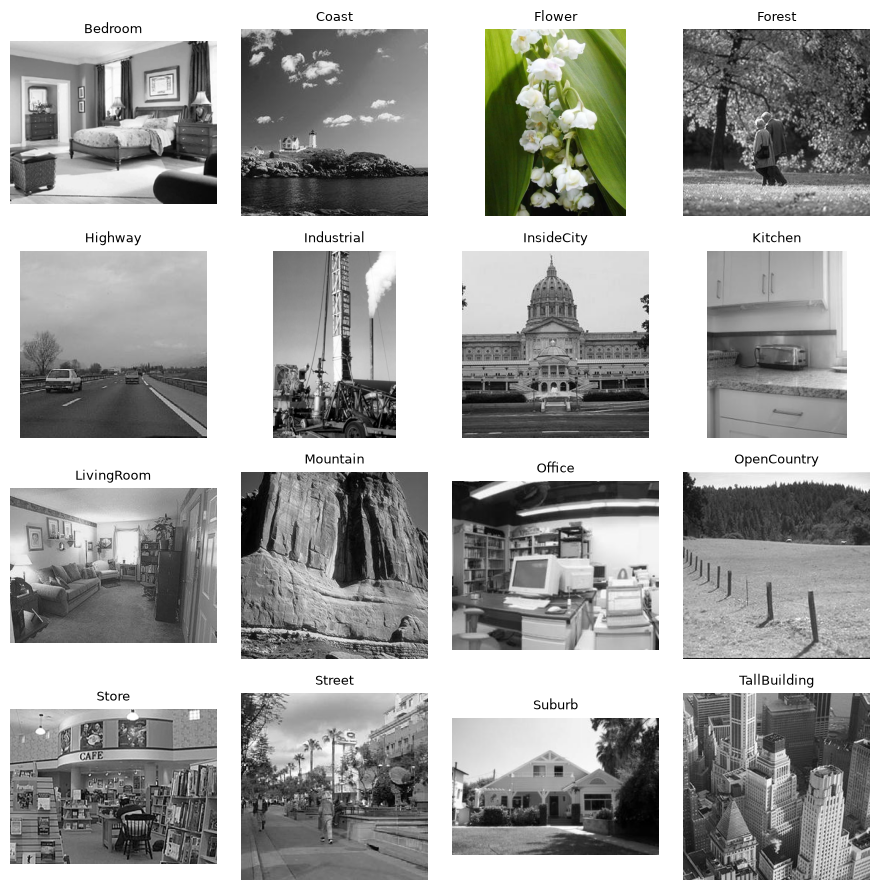

In [12]:
# The 16 labeled images of the headline seed: worth a look, since everything below depends on these 16 pictures
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for ax, c, p in zip(axes.ravel(), EXPECTED_CLASSES, support[HEADLINE_SEED]['paths']):
    ax.imshow(load_rgb(p)); ax.set_title(c, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'oneshot_support_headline_seed.png', dpi=120); plt.show()

## Embed everything, model by model
For each model: the test images, the support views of every seed, and (for CLIP and SigLIP, if `RUN_BLEND`) the class text
embeddings. Everything is cached; a model that fails to load is reported and skipped.

In [13]:
emb_test, emb_support, text_emb, failed = {}, {}, {}, []

for key in ENABLED_MODELS:
    kind = MODEL_SPECS[key]['kind']
    variants = FEATURE_VARIANTS[kind]
    print(f'\n=== {key} ({MODEL_SPECS[key]["repo"]}) ===')
    t_model = time.time()
    try:
        state = {}
        def get_bundle():
            if 'b' not in state:
                state['b'] = load_bundle(key)
                state['dev'] = choose_run_device(state['b'], test_images[:8])
            return state['b'], state['dev']

        def build_test():
            b, dev = get_bundle()
            d = embed_images(b, test_images, dev, BATCH_SIZE)
            d['labels'] = test_labels
            return d
        data = cached_npz(CACHE_DIR / f'test_{key}.npz', build_test,
                          check=lambda d: all(v in d for v in variants) and len(d['labels']) == len(test_labels) and bool((d['labels'] == test_labels).all()))
        emb_test[key] = {v: data[v] for v in variants}

        emb_support[key] = {}
        for s in range(N_SEEDS):
            names = np.array([str(p) for p in support[s]['paths']])
            def build_support(s=s, names=names):
                b, dev = get_bundle()
                flat = [im for views in support[s]['views'] for im in views]
                d = embed_images(b, flat, dev, BATCH_SIZE, quiet=True)
                out = {v: d[v].reshape(NUM_CLASSES, 1 + N_AUG, -1) for v in d}
                out['paths'] = names
                return out
            sd = cached_npz(CACHE_DIR / f'os_{key}_support_s{s}_aug{N_AUG}.npz', build_support,
                            check=lambda d, names=names: all(v in d for v in variants) and bool((d['paths'] == names).all())
                                                          and d[variants[0]].shape[1] == 1 + N_AUG)
            emb_support[key][s] = {v: sd[v] for v in variants}
            print(f'  support set seed {s} embedded')

        if RUN_BLEND and kind in ('clip', 'siglip'):
            def build_text():
                b, dev = get_bundle()
                return dict(emb=class_text_embeddings(b, 'descriptive', 'ensemble', dev), sig=np.array(PROMPT_SIG))
            tdata = cached_npz(CACHE_DIR / f'os_{key}_text.npz', build_text,
                               check=lambda d: 'sig' in d and str(d['sig']) == PROMPT_SIG and 'emb' in d)
            text_emb[key] = tdata['emb']
        print(f'  done in {time.time() - t_model:.0f}s')
    except Exception as e:
        print(f'  !! {key} failed: {type(e).__name__}: {e}')
        failed.append(key)
        emb_test.pop(key, None); emb_support.pop(key, None)
    state.clear(); gc.collect()

models_ok = [k for k in ENABLED_MODELS if k in emb_test and k in emb_support and len(emb_support[k]) == N_SEEDS]
print('\nready:', models_ok, '| failed:', failed)


=== clip-b16 (openai/clip-vit-base-patch16) ===


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


loaded clip-b16  (openai/clip-vit-base-patch16, 150M parameters, 2s)
  support set seed 0 embedded
  support set seed 1 embedded
  support set seed 2 embedded
  support set seed 3 embedded
  support set seed 4 embedded
  done in 69s

=== clip-l14 (openai/clip-vit-large-patch14) ===
loaded clip-l14  (openai/clip-vit-large-patch14, 428M parameters, 1s)
  support set seed 0 embedded
  support set seed 1 embedded
  support set seed 2 embedded
  support set seed 3 embedded
  support set seed 4 embedded
  done in 293s

=== siglip-b16-224 (google/siglip-base-patch16-224) ===
loaded siglip-b16-224  (google/siglip-base-patch16-224, 203M parameters, 1s)
  support set seed 0 embedded
  support set seed 1 embedded
  support set seed 2 embedded
  support set seed 3 embedded
  support set seed 4 embedded
  done in 73s

=== siglip-so400m-384 (google/siglip-so400m-patch14-384) ===
loaded siglip-so400m-384  (google/siglip-so400m-patch14-384, 878M parameters, 1s)
  support set seed 0 embedded
  support 

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


loaded dinov2-base  (facebook/dinov2-base, 87M parameters, 36s)
    16/400 images | 2s elapsed | projected total 48s
    80/400 images | 10s elapsed | projected total 48s
    160/400 images | 19s elapsed | projected total 48s
    240/400 images | 29s elapsed | projected total 48s
    320/400 images | 38s elapsed | projected total 48s
    400/400 images | 48s elapsed | projected total 48s
  support set seed 0 embedded
  support set seed 1 embedded
  support set seed 2 embedded
  support set seed 3 embedded
  support set seed 4 embedded
  done in 170s

=== dinov2-large (facebook/dinov2-large) ===


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


loaded dinov2-large  (facebook/dinov2-large, 304M parameters, 126s)
    16/400 images | 6s elapsed | projected total 160s
    80/400 images | 31s elapsed | projected total 157s
    160/400 images | 63s elapsed | projected total 157s
    240/400 images | 94s elapsed | projected total 157s
    320/400 images | 125s elapsed | projected total 157s
    400/400 images | 157s elapsed | projected total 157s
  support set seed 0 embedded
  support set seed 1 embedded
  support set seed 2 embedded
  support set seed 3 embedded
  support set seed 4 embedded
  done in 562s

ready: ['clip-b16', 'clip-l14', 'siglip-b16-224', 'siglip-so400m-384', 'dinov2-base', 'dinov2-large'] | failed: []


## One-shot accuracy
For every model, feature variant, prototype type (`noaug` / `aug`) and seed: build the 16 prototypes from that seed's labeled
images and classify the test images by highest cosine similarity.

In [14]:
rows = []
for key in models_ok:
    kind = MODEL_SPECS[key]['kind']
    for variant in FEATURE_VARIANTS[kind]:
        for proto in ('noaug', 'aug'):
            for s in range(N_SEEDS):
                P = make_prototypes(emb_support[key][s][variant], proto)             # [16, D]
                pred = (emb_test[key][variant] @ P.T).argmax(1)
                rows.append(dict(model=key, variant=variant, proto=proto, seed=s, acc=accuracy(pred, test_labels)))

summary = []
print(f"{'model':<20}{'variant':<11}{'proto':<7}{'mean':>8}{'std':>8}{'min':>8}{'max':>8}{'headline seed':>15}")
for key in models_ok:
    kind = MODEL_SPECS[key]['kind']
    for variant in FEATURE_VARIANTS[kind]:
        for proto in ('noaug', 'aug'):
            accs = [r['acc'] for r in rows if r['model'] == key and r['variant'] == variant and r['proto'] == proto]
            m, sd = mean_std(accs)
            hs = next(r['acc'] for r in rows if r['model'] == key and r['variant'] == variant and r['proto'] == proto and r['seed'] == HEADLINE_SEED)
            declared = (variant == HEADLINE_VARIANT[kind]) and proto == 'aug'
            summary.append(dict(model=key, variant=variant, proto=proto, mean=m, std=sd, min=min(accs), max=max(accs), headline_seed=hs, declared=declared))
            print(f"{key:<20}{variant:<11}{proto:<7}{m:>8.4f}{sd:>8.4f}{min(accs):>8.4f}{max(accs):>8.4f}{hs:>15.4f}{'   <- declared headline variant' if declared else ''}")
print(f'\nchance = {1 / NUM_CLASSES:.4f}. std is across {N_SEEDS} different support sets (the choice of the 16 images); one test-set standard error is about ±0.02.')

model               variant    proto      mean     std     min     max  headline seed
clip-b16            img        noaug    0.7150  0.0418  0.6525  0.7650         0.6525
clip-b16            img        aug      0.7265  0.0511  0.6625  0.7850         0.6625   <- declared headline variant
clip-l14            img        noaug    0.7165  0.0481  0.6600  0.7600         0.6600
clip-l14            img        aug      0.7190  0.0544  0.6575  0.7775         0.6575   <- declared headline variant
siglip-b16-224      img        noaug    0.7615  0.0824  0.6650  0.8475         0.6875
siglip-b16-224      img        aug      0.7805  0.0673  0.7050  0.8525         0.7200   <- declared headline variant
siglip-so400m-384   img        noaug    0.7660  0.0429  0.7025  0.8125         0.7025
siglip-so400m-384   img        aug      0.7795  0.0512  0.7150  0.8250         0.7350   <- declared headline variant
dinov2-base         cls        noaug    0.7535  0.0476  0.6900  0.8150         0.7300
dinov2-base     

model                  seed 0   seed 1   seed 2   seed 3   seed 4
clip-b16               0.6625   0.7850   0.7575   0.7425   0.6850
clip-l14               0.6575   0.7775   0.7550   0.7400   0.6650
siglip-b16-224         0.7200   0.8525   0.7850   0.8400   0.7050
siglip-so400m-384      0.7350   0.8225   0.8250   0.8000   0.7150
dinov2-base            0.7325   0.7850   0.7850   0.8050   0.7400
dinov2-large           0.6750   0.7775   0.7000   0.7900   0.6725


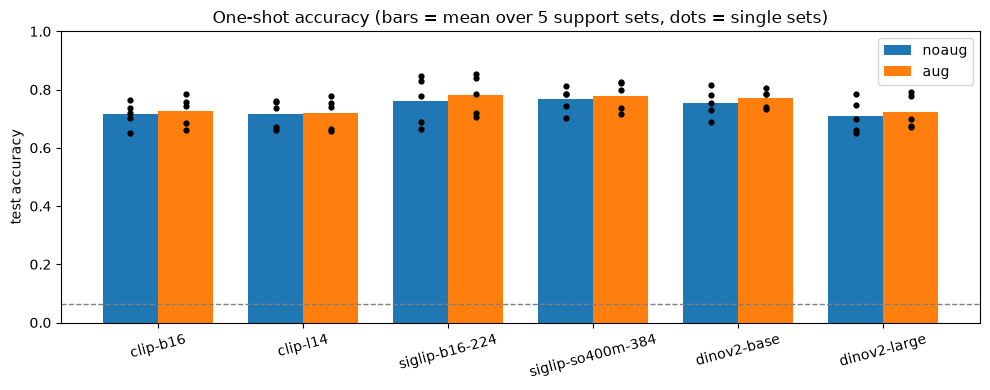

In [15]:
# Per-seed accuracies of the declared variant (aug prototypes): how much does the choice of the 16 images matter?
print(f"{'model':<20}" + ''.join(f'{"seed " + str(s):>9}' for s in range(N_SEEDS)))
for key in models_ok:
    v = HEADLINE_VARIANT[MODEL_SPECS[key]['kind']]
    accs = [next(r['acc'] for r in rows if r['model'] == key and r['variant'] == v and r['proto'] == 'aug' and r['seed'] == s) for s in range(N_SEEDS)]
    print(f'{key:<20}' + ''.join(f'{a:>9.4f}' for a in accs))

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.38
for j, proto in enumerate(('noaug', 'aug')):
    for i, key in enumerate(models_ok):
        v = HEADLINE_VARIANT[MODEL_SPECS[key]['kind']]
        accs = [r['acc'] for r in rows if r['model'] == key and r['variant'] == v and r['proto'] == proto]
        x = i + (j - 0.5) * w
        ax.bar(x, np.mean(accs), w, color=['tab:blue', 'tab:orange'][j], label=proto if i == 0 else None)
        ax.scatter([x] * len(accs), accs, color='k', s=12, zorder=3)
ax.axhline(1 / NUM_CLASSES, color='gray', ls='--', lw=1)
ax.set_xticks(range(len(models_ok))); ax.set_xticklabels(models_ok, rotation=15)
ax.set_ylim(0, 1); ax.set_ylabel('test accuracy'); ax.set_title(f'One-shot accuracy (bars = mean over {N_SEEDS} support sets, dots = single sets)'); ax.legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'oneshot_accuracy.png', dpi=150); plt.show()

## Where does it go wrong?
Confusions for the model with the highest mean accuracy (declared variant, `aug` prototypes), on the headline seed.
This is descriptive, to understand the errors; it is not a model-selection step.

siglip-b16-224 (img, aug) | headline seed 0 | accuracy 0.7200

  Forest        0.000
  InsideCity    0.080
  Kitchen       0.440
  Street        0.560
  Bedroom       0.600
  Mountain      0.720
  Coast         0.800
  Flower        0.840
  OpenCountry   0.840
  TallBuilding  0.840
  Store         0.880
  LivingRoom    0.960
  Office        0.960
  Highway       1.000
  Industrial    1.000
  Suburb        1.000

most frequent confusions (true -> predicted):
  Forest        -> OpenCountry   25
  Kitchen       -> LivingRoom    13
  Bedroom       -> LivingRoom    10
  Mountain      -> OpenCountry   6
  InsideCity    -> Suburb        6
  Street        -> Highway       5
  InsideCity    -> Street        5
  Street        -> TallBuilding  4


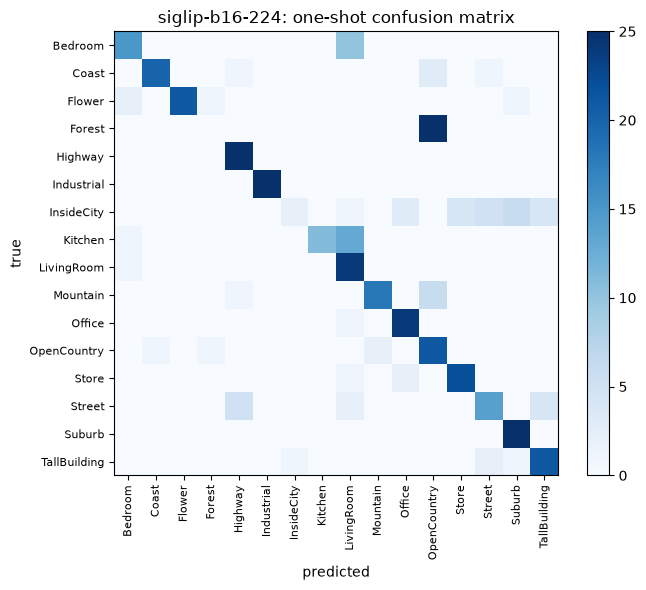

In [16]:
best = max([s for s in summary if s['declared']], key=lambda s: s['mean'])
key, variant = best['model'], best['variant']
P = make_prototypes(emb_support[key][HEADLINE_SEED][variant], 'aug')
pred = (emb_test[key][variant] @ P.T).argmax(1)
cm = confusion_matrix(pred, test_labels, NUM_CLASSES)
pc = per_class_accuracy(pred, test_labels, NUM_CLASSES)
print(f'{key} ({variant}, aug) | headline seed {HEADLINE_SEED} | accuracy {accuracy(pred, test_labels):.4f}\n')
for c, a in sorted(zip(EXPECTED_CLASSES, pc), key=lambda x: x[1]):
    print(f'  {c:<14}{a:.3f}')
print('\nmost frequent confusions (true -> predicted):')
for n, t, p in top_confusions(cm, EXPECTED_CLASSES, 8):
    print(f'  {t:<14}-> {p:<14}{n}')

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(EXPECTED_CLASSES, rotation=90, fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(EXPECTED_CLASSES, fontsize=8)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'{key}: one-shot confusion matrix')
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(RESULTS_DIR / 'oneshot_confusion.png', dpi=150); plt.show()

## Optional: text classifier + image prototypes
Each test image gets two sets of 16 scores: similarity to the **text** class embeddings (zero-shot, `descriptive` phrases and
`ensemble` templates, as in the zero-shot notebook) and similarity to the **image prototypes** (declared variant, `aug`).
Each score set is standardised per test image across the 16 classes (z-score) and the two are mixed:
`score = alpha * text + (1 - alpha) * prototype`, with `alpha = BLEND_ALPHA = 0.5` fixed in advance.

The text side must come from CLIP or SigLIP; the prototype side can come from any model, so the table mixes them freely
(for example SigLIP text with DINOv2 prototypes). Cells are mean accuracy over the `N_SEEDS` support sets.

In [17]:
blend_rows, text_models = [], [k for k in models_ok if k in text_emb]
if not RUN_BLEND or not text_models:
    print('blend section skipped (RUN_BLEND is off or no CLIP/SigLIP model with text embeddings is available)')
else:
    def proto_scores(pk, s):
        v = HEADLINE_VARIANT[MODEL_SPECS[pk]['kind']]
        return emb_test[pk][v] @ make_prototypes(emb_support[pk][s][v], 'aug').T
    def text_scores(tk):
        return emb_test[tk]['img'] @ text_emb[tk].T

    zs = {tk: accuracy(text_scores(tk).argmax(1), test_labels) for tk in text_models}
    for tk in text_models:
        for pk in models_ok:
            for s in range(N_SEEDS):
                mix = BLEND_ALPHA * zscore_rows(text_scores(tk)) + (1 - BLEND_ALPHA) * zscore_rows(proto_scores(pk, s))
                blend_rows.append(dict(text_model=tk, proto_model=pk, seed=s, alpha=BLEND_ALPHA, acc=accuracy(mix.argmax(1), test_labels)))

    print(f'mean test accuracy of the blend (alpha = {BLEND_ALPHA}); rows = text model, columns = prototype model\n')
    print('text model (zero-shot alone)'.ljust(36) + ''.join(pk.rjust(19) for pk in models_ok))
    for tk in text_models:
        cells = []
        for pk in models_ok:
            m, sd = mean_std([r['acc'] for r in blend_rows if r['text_model'] == tk and r['proto_model'] == pk])
            cells.append(f'{m:.3f} ± {sd:.3f}')
        label = f'{tk} ({zs[tk]:.3f})'
        print(label.ljust(36) + ''.join(c.rjust(19) for c in cells))
    ref = []
    for pk in models_ok:
        pm = [s['mean'] for s in summary if s['model'] == pk and s['declared']][0]
        ref.append(f'{pk} {pm:.3f}')
    print('\nprototype-only accuracy (alpha = 0) for reference: ' + ', '.join(ref))

mean test accuracy of the blend (alpha = 0.5); rows = text model, columns = prototype model

text model (zero-shot alone)                   clip-b16           clip-l14     siglip-b16-224  siglip-so400m-384        dinov2-base       dinov2-large
clip-b16 (0.858)                          0.860 ± 0.016      0.869 ± 0.020      0.885 ± 0.020      0.888 ± 0.026      0.846 ± 0.019      0.839 ± 0.023
clip-l14 (0.870)                          0.876 ± 0.015      0.871 ± 0.028      0.898 ± 0.015      0.895 ± 0.017      0.857 ± 0.012      0.849 ± 0.021
siglip-b16-224 (0.892)                    0.878 ± 0.029      0.875 ± 0.029      0.895 ± 0.031      0.894 ± 0.027      0.852 ± 0.020      0.839 ± 0.020
siglip-so400m-384 (0.868)                 0.872 ± 0.026      0.874 ± 0.030      0.891 ± 0.026      0.887 ± 0.025      0.850 ± 0.020      0.841 ± 0.016

prototype-only accuracy (alpha = 0) for reference: clip-b16 0.727, clip-l14 0.719, siglip-b16-224 0.780, siglip-so400m-384 0.779, dinov2-base 0.770, di

### Sensitivity to the mixing weight (analysis only)
How much the blend depends on `alpha` for one text/prototype pair. **Do not pick `alpha` from this table**: there is no
validation set, so choosing it by test accuracy would be tuning on the test set. It is here to show whether the conclusion is
robust to the weight.

In [18]:
SWEEP_PAIR = ('siglip-so400m-384', 'dinov2-large')       # (text model, prototype model); edit if you like
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]
if RUN_BLEND and SWEEP_PAIR[0] in text_models and SWEEP_PAIR[1] in models_ok:
    tk, pk = SWEEP_PAIR
    print(f'text = {tk}, prototypes = {pk}')
    print(f"{'alpha (weight on text)':<26}{'mean':>8}{'std':>8}")
    for a in ALPHAS:
        accs = []
        for s in range(N_SEEDS):
            mix = a * zscore_rows(text_scores(tk)) + (1 - a) * zscore_rows(proto_scores(pk, s))
            accs.append(accuracy(mix.argmax(1), test_labels))
        m, sd = mean_std(accs)
        print(f'{a:<26}{m:>8.4f}{sd:>8.4f}')
else:
    print('sweep pair not available')

text = siglip-so400m-384, prototypes = dinov2-large
alpha (weight on text)        mean     std
0.0                         0.7230  0.0567
0.25                        0.7715  0.0405
0.5                         0.8410  0.0162
0.75                        0.8925  0.0085
1.0                         0.8675  0.0000


## Save results

In [19]:
meta = dict(torch=torch.__version__, transformers=transformers.__version__, device=str(DEVICE),
            models={k: MODEL_SPECS[k]['repo'] for k in models_ok}, failed=failed, n_seeds=N_SEEDS, headline_seed=HEADLINE_SEED,
            n_aug=N_AUG, blend_alpha=BLEND_ALPHA, headline_variant=HEADLINE_VARIANT, n_test=int(len(test_labels)))
(RESULTS_DIR / 'oneshot_results.json').write_text(json.dumps(dict(meta=meta, rows=rows, summary=summary, blend_rows=blend_rows), indent=1))
with open(RESULTS_DIR / 'oneshot_results.csv', 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
print('saved to', RESULTS_DIR)

saved to a3_results


## Reading these results
- With one image per class, **the choice of that image changes the result**: compare the spread across seeds with the gaps between models.
  A model that wins on one support set but not on average is not a reliable winner. Report mean ± std.
- Test accuracy has its own noise (about ±2 points for one model on 400 images), on top of the support-set variance.
- `aug` versus `noaug` shows whether averaging augmented copies stabilises the single-image prototype.
- DINOv2 has no text side, so it can only be used here (and in the blend as the prototype provider).
- No labeled validation data exists: picking a final recipe from these numbers is a test-set choice, so say so in the report.

In [21]:
key, v = 'siglip-b16-224', 'img'
F_, O_ = EXPECTED_CLASSES.index('Forest'), EXPECTED_CLASSES.index('OpenCountry')
for s in range(N_SEEDS):
    P = make_prototypes(emb_support[key][s][v], 'aug')
    pred = (emb_test[key][v] @ P.T).argmax(1)
    pc = per_class_accuracy(pred, test_labels, NUM_CLASSES)
    print(f'seed {s}: overall {accuracy(pred, test_labels):.3f} | Forest {pc[F_]:.2f} | OpenCountry {pc[O_]:.2f} | '
          f'Forest file {support[s]["paths"][F_].name}')

seed 0: overall 0.720 | Forest 0.00 | OpenCountry 0.84 | Forest file image_0132.jpg
seed 1: overall 0.853 | Forest 0.96 | OpenCountry 0.44 | Forest file image_0003.jpg
seed 2: overall 0.785 | Forest 0.88 | OpenCountry 0.76 | Forest file image_0054.jpg
seed 3: overall 0.840 | Forest 0.76 | OpenCountry 0.40 | Forest file image_0039.jpg
seed 4: overall 0.705 | Forest 0.00 | OpenCountry 0.76 | Forest file image_0020.jpg


In [22]:
tk, pk = 'siglip-so400m-384', 'siglip-so400m-384'      # edit to any text model / prototype model in your blend table
for a in (0.0, 0.5):
    accs = []
    for s in range(N_SEEDS):
        mix = a * zscore_rows(text_scores(tk)) + (1 - a) * zscore_rows(proto_scores(pk, s))
        accs.append(accuracy(mix.argmax(1), test_labels))
    print(f'alpha {a}: ' + ' '.join(f'{x:.3f}' for x in accs) + f' | mean {np.mean(accs):.3f} std {np.std(accs, ddof=1):.3f}')

alpha 0.0: 0.735 0.823 0.825 0.800 0.715 | mean 0.779 std 0.051
alpha 0.5: 0.868 0.925 0.875 0.897 0.868 | mean 0.887 std 0.025


In [23]:
tk, pk = 'siglip-so400m-384', 'siglip-so400m-384'
zs_ok = text_scores(tk).argmax(1) == test_labels
for s in range(N_SEEDS):
    mix = 0.5 * zscore_rows(text_scores(tk)) + 0.5 * zscore_rows(proto_scores(pk, s))
    ok = mix.argmax(1) == test_labels
    print(f'seed {s}: blend fixes {int((ok & ~zs_ok).sum()):3d}, breaks {int((~ok & zs_ok).sum()):3d} | net {int(ok.sum() - zs_ok.sum()):+d}')

seed 0: blend fixes  20, breaks  20 | net +0
seed 1: blend fixes  29, breaks   6 | net +23
seed 2: blend fixes  20, breaks  17 | net +3
seed 3: blend fixes  21, breaks   9 | net +12
seed 4: blend fixes  24, breaks  24 | net +0


In [24]:
tk, pk = 'siglip-so400m-384', 'siglip-so400m-384'
zs_ok = text_scores(tk).argmax(1) == test_labels
for s in (0, 4, 1):
    mix = 0.5 * zscore_rows(text_scores(tk)) + 0.5 * zscore_rows(proto_scores(pk, s))
    ok = mix.argmax(1) == test_labels
    fixes, breaks = (ok & ~zs_ok), (~ok & zs_ok)
    print(f'seed {s}')
    print('  fixes by true class :', {EXPECTED_CLASSES[c]: int((fixes & (test_labels == c)).sum()) for c in range(16) if (fixes & (test_labels == c)).any()})
    print('  breaks by true class:', {EXPECTED_CLASSES[c]: int((breaks & (test_labels == c)).sum()) for c in range(16) if (breaks & (test_labels == c)).any()})

seed 0
  fixes by true class : {'Forest': 1, 'Industrial': 3, 'Office': 1, 'OpenCountry': 6, 'Suburb': 2, 'TallBuilding': 7}
  breaks by true class: {'Bedroom': 1, 'Forest': 11, 'InsideCity': 2, 'Kitchen': 6}
seed 4
  fixes by true class : {'Forest': 2, 'Industrial': 3, 'InsideCity': 3, 'Office': 1, 'OpenCountry': 3, 'Store': 2, 'Street': 1, 'Suburb': 2, 'TallBuilding': 7}
  breaks by true class: {'Coast': 8, 'Forest': 7, 'InsideCity': 2, 'LivingRoom': 7}
seed 1
  fixes by true class : {'Forest': 3, 'Industrial': 3, 'InsideCity': 6, 'Office': 1, 'OpenCountry': 4, 'Store': 2, 'Street': 1, 'Suburb': 2, 'TallBuilding': 7}
  breaks by true class: {'InsideCity': 1, 'Kitchen': 1, 'Mountain': 1, 'Store': 1, 'Street': 2}
